In [1]:
#Cell 1: Install Dependencies

!pip install -q transformers datasets evaluate accelerate torchvision albumentations

In [14]:
#Cell 2: Download Dataset
#   Combined PlantVillage (38 classes) + PlantDoc (In-Field Real Images)

import os
import shutil
from pathlib import Path

# 1. Download Full 38-class PlantVillage Dataset from Kaggle
os.environ['KAGGLE_CONFIG_DIR'] = '/content'
!rm -rf /content/data /content/plantdoc
!mkdir -p /content/data
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset -p /content/data --unzip

# 2. Clone PlantDoc (Real-World Field Dataset)
!git clone https://github.com/pratikkayal/PlantDoc-Dataset.git /content/plantdoc

# 3. Locate the PlantVillage train folder
possible_paths = [
    Path("/content/data/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"),
    Path("/content/data/New Plant Diseases Dataset(Augmented)/train"),
    Path("/content/data/train")
]
pv_train = None
for p in possible_paths:
    if p.exists() and len(list(p.iterdir())) >= 30:
        pv_train = p
        break

assert pv_train is not None, "Could not find PlantVillage train folder. Check /content/data structure."
print(f"PlantVillage train directory located at: {pv_train}")

# 4. Map PlantDoc classes to PlantVillage directory names
# Note: Case-insensitive mapping handles variations like 'healthy' vs 'Healthy'
pv_folders = {f.name.lower(): f.name for f in pv_train.iterdir() if f.is_dir()}

name_map = {
    "Apple Scab Leaf": "apple___apple_scab",
    "Apple leaf": "apple___healthy",
    "Apple rust leaf": "apple___cedar_apple_rust",
    "Bell_pepper leaf": "pepper,_bell___healthy",
    "Bell_pepper leaf spot": "pepper,_bell___bacterial_spot",
    "Corn Gray leaf spot": "corn_(maize)___cercospora_leaf_spot gray_leaf_spot",
    "Corn leaf blight": "corn_(maize)___northern_leaf_blight",
    "Corn rust leaf": "corn_(maize)___common_rust_",
    "Grape leaf": "grape___healthy",
    "Grape leaf black rot": "grape___black_rot",
    "Potato leaf early blight": "potato___early_blight",
    "Potato leaf late blight": "potato___late_blight",
    "Tomato Early blight leaf": "tomato___early_blight",
    "Tomato Septoria leaf spot": "tomato___septoria_leaf_spot",
    "Tomato leaf": "tomato___healthy",
    "Tomato leaf bacterial spot": "tomato___bacterial_spot",
    "Tomato leaf late blight": "tomato___late_blight",
    "Tomato leaf mosaic virus": "tomato___tomato_mosaic_virus",
    "Tomato leaf yellow virus": "tomato___tomato_yellow_leaf_curl_virus",
    "Tomato mold leaf": "tomato___leaf_mold",
    "Tomato two spotted spider mites leaf": "tomato___spider_mites two-spotted_spider_mite"
}

# Combine both train and test splits from PlantDoc into our training pool
plantdoc_dirs = [Path("/content/plantdoc/train"), Path("/content/plantdoc/test")]
copied_count = 0

for p_dir in plantdoc_dirs:
    if not p_dir.exists():
        continue
    for doc_folder in p_dir.iterdir():
        if not doc_folder.is_dir():
            continue
        mapped_key = name_map.get(doc_folder.name)
        if mapped_key and mapped_key in pv_folders:
            target_folder = pv_train / pv_folders[mapped_key]
            for img in doc_folder.glob("*.*"):
                if img.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                    dest = target_folder / f"plantdoc_{p_dir.name}_{img.name}"
                    shutil.copy(img, dest)
                    copied_count += 1

print(f"Successfully injected {copied_count} real-world in-field images from PlantDoc into PlantVillage!")

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [00:39<00:00, 74.0MB/s]

Cloning into '/content/plantdoc'...
remote: Enumerating objects: 2670, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 2670 (delta 22), reused 22 (delta 22), pack-reused 2635 (from 1)
Receiving objects: 100% (2670/2670), 932.92 MiB | 21.97 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Updating files: 100% (2581/2581), done.
PlantVillage train directory located at: /content/data/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Successfully injected 1749 real-world in-field images from PlantDoc into PlantVillage!


In [15]:
# Cell 3: Dataset Preparation & Albumentations Augmentation

import torch
import numpy as np
from PIL import Image
from torchvision.datasets import ImageFolder
from transformers import AutoImageProcessor
import albumentations as A

MODEL_CHECKPOINT = "google/vit-base-patch16-224"

processor = AutoImageProcessor.from_pretrained(MODEL_CHECKPOINT)

# Load full merged dataset
base_dataset = ImageFolder(str(pv_train))
class_names = base_dataset.classes
num_classes = len(class_names)
id2label = {i: label for i, label in enumerate(class_names)}
label2id = {label: i for i, label in enumerate(class_names)}

print(f"Total classes found: {num_classes}")
assert num_classes == 38, f"Expected 38 classes, but got {num_classes}"

# Robust field augmentations: handling varying lighting, sun glare, blur, and orientation
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.1, p=0.7),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    A.GaussNoise(p=0.3),
])

val_transform = A.Compose([
    A.Resize(224, 224),
])

class CombinedPlantDataset(torch.utils.data.Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = np.array(Image.open(path).convert("RGB"))

        if self.transform:
            augmented = self.transform(image=image)
            image = augmented["image"]

        inputs = processor(image, return_tensors="pt")
        inputs["pixel_values"] = inputs["pixel_values"].squeeze(0)
        inputs["labels"] = torch.tensor(label, dtype=torch.long)
        return inputs

# 85/15 Train-Validation Split
indices = list(range(len(base_dataset)))
np.random.seed(42)
np.random.shuffle(indices)
split = int(0.85 * len(indices))
train_indices, val_indices = indices[:split], indices[split:]

train_samples = [base_dataset.samples[i] for i in train_indices]
val_samples = [base_dataset.samples[i] for i in val_indices]

train_dataset = CombinedPlantDataset(train_samples, transform=train_transform)
val_dataset = CombinedPlantDataset(val_samples, transform=val_transform)

print(f"Training samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}")



Total classes found: 38
Training samples: 61237, Validation samples: 10807


In [16]:
# Cell 4: Initialize ViT Model & Metrics

from transformers import AutoConfig, AutoModelForImageClassification
import evaluate

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    return accuracy_metric.compute(predictions=preds, references=labels)

def collate_fn(examples):
    pixel_values = torch.stack([example["pixel_values"] for example in examples])
    labels = torch.tensor([example["labels"] for example in examples])
    return {"pixel_values": pixel_values, "labels": labels}

# Set 38 labels cleanly in the config
config = AutoConfig.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=num_classes,
    id2label=id2label,
    label2id=label2id
)

model = AutoModelForImageClassification.from_pretrained(
    MODEL_CHECKPOINT,
    config=config,
    ignore_mismatched_sizes=True
)



[transformers] You passed `num_labels=38` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([38])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([38, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [17]:
# let me just save them to my drive in case I lose connection

from google.colab import drive
import os

# Mount Drive so weights survive disconnects
drive.mount('/content/drive')

# Directory on your Google Drive where checkpoints will be stored
GDRIVE_SAVE_DIR = "/content/drive/MyDrive/CropDiseaseDetection_ViT"
os.makedirs(GDRIVE_SAVE_DIR, exist_ok=True)
print(f"Checkpoints will be saved to: {GDRIVE_SAVE_DIR}")

Mounted at /content/drive
Checkpoints will be saved to: /content/drive/MyDrive/CropDiseaseDetection_ViT


In [22]:
# Cell 5: Training

import os
import torch
from transformers import TrainingArguments, Trainer
from transformers.trainer_utils import get_last_checkpoint

# Directory in Google Drive for all checkpoints
CHECKPOINT_DIR = "/content/drive/MyDrive/CropDiseaseDetection_ViT/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",          # Evaluate at end of each epoch
    save_strategy="epoch",          # Save checkpoint at end of each epoch
    save_total_limit=5,             # Keep 2 latest checkpoints
    learning_rate=5e-5,
    num_train_epochs=3,             # 3 epouch only
    weight_decay=0.01,
    logging_steps=50,
    load_best_model_at_end=True,    # Loads the checkpoint with highest accuracy
    metric_for_best_model="accuracy",
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    processing_class=processor,
)

# Auto-resume logic
last_checkpoint = get_last_checkpoint(CHECKPOINT_DIR)

if last_checkpoint is not None:
    print(f"--> Found existing checkpoint in Google Drive: {last_checkpoint}")
    print("--> Resuming training from last checkpoint automatically!")
    train_result = trainer.train(resume_from_checkpoint=last_checkpoint)
else:
    print("--> No previous checkpoint found. Starting fresh training from Epoch 1...")
    train_result = trainer.train()



--> No previous checkpoint found. Starting fresh training from Epoch 1...


Epoch,Training Loss,Validation Loss,Accuracy
1,0.150379,0.046304,0.986213
2,0.069378,0.037280,0.988711
3,0.050851,0.031172,0.989729


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

In [27]:
# research_paper_assets

import os
import json
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from transformers import ViTForImageClassification

RESEARCH_DIR = "/content/research_paper_assets"
os.makedirs(RESEARCH_DIR, exist_ok=True)
print(f"Generating all research paper artifacts in: {RESEARCH_DIR}...")

# -------------------------------------------------------------
# 1. MODEL ARCHITECTURE & COMPLEXITY METRICS (Table 1 in Paper)
# -------------------------------------------------------------
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# Measure inference latency on GPU & CPU
dummy_input = torch.randn(1, 3, 224, 224).to(model.device)
# Warmup
for _ in range(10):
    _ = model(dummy_input)

# Benchmark GPU Latency (mean of 100 runs)
timings = []
with torch.no_grad():
    for _ in range(100):
        start = time.perf_counter()
        _ = model(dummy_input)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        timings.append((time.perf_counter() - start) * 1000)

avg_latency_ms = np.mean(timings)
fps = 1000.0 / avg_latency_ms

arch_specs = {
    "Model Architecture": "Vision Transformer (google/vit-base-patch16-224)",
    "Patch Size": "16x16",
    "Hidden Dimension (D)": 768,
    "Number of Attention Heads": 12,
    "Number of Transformer Layers": 12,
    "Total Parameters": f"{total_params:,}",
    "Trainable Parameters": f"{trainable_params:,}",
    "Model Size on Disk (MB)": round(os.path.getsize(f"{FINAL_MODEL_DIR}/model.safetensors") / (1024 * 1024), 2) if os.path.exists(f"{FINAL_MODEL_DIR}/model.safetensors") else "N/A",
    "Mean Inference Latency (ms)": round(avg_latency_ms, 2),
    "Inference Throughput (FPS)": round(fps, 1),
    "Dataset": "PlantVillage (38 Classes) + PlantDoc In-Field Real-World Injected",
    "Total Training Images": len(train_dataset),
    "Total Validation Images": len(val_dataset),
    "Batch Size": 32,
    "Learning Rate": 5e-5,
    "Optimizer": "AdamW (weight_decay=0.01)"
}

with open(f"{RESEARCH_DIR}/model_architecture_specifications.json", "w") as f:
    json.dump(arch_specs, f, indent=4)
print("✓ Saved Model Architecture Specs (Table 1)")

# -------------------------------------------------------------
# 2. TRAINING PROGRESSION LOGS & LEARNING CURVES (Figure 1 in Paper)
# -------------------------------------------------------------
log_history = trainer.state.log_history
train_epochs, train_loss = [], []
eval_epochs, eval_loss, eval_acc = [], [], []

for entry in log_history:
    if "loss" in entry and "epoch" in entry:
        train_epochs.append(entry["epoch"])
        train_loss.append(entry["loss"])
    if "eval_loss" in entry and "epoch" in entry:
        eval_epochs.append(entry["epoch"])
        eval_loss.append(entry["eval_loss"])
        eval_acc.append(entry["eval_accuracy"])

# Plot Academic-grade Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curve
if train_loss and train_epochs:
    ax1.plot(train_epochs, train_loss, label="Training Loss", color="#1f77b4", lw=2)
if eval_loss and eval_epochs:
    ax1.plot(eval_epochs, eval_loss, label="Validation Loss", color="#ff7f0e", marker="o", lw=2)
ax1.set_title("Training and Validation Loss", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Cross-Entropy Loss", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

# Accuracy Curve
if eval_acc and eval_epochs:
    ax2.plot(eval_epochs, [acc * 100 for acc in eval_acc], label="Validation Accuracy (%)", color="#2ca02c", marker="s", lw=2)
ax2.set_title("Validation Accuracy Progression", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy (%)", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig(f"{RESEARCH_DIR}/figure1_learning_curves.png", dpi=300)
plt.close()
print("✓ Saved High-Res Figure 1: Learning Curves")

# -------------------------------------------------------------
# 3. COMPREHENSIVE VALIDATION EVALUATION (Predictions & Ground Truth)
# -------------------------------------------------------------
print("Evaluating entire validation set for rigorous metrics...")
eval_preds = trainer.predict(val_dataset)
y_pred = np.argmax(eval_preds.predictions, axis=1)
y_true = eval_preds.label_ids

class_labels = [id2label[i] for i in range(len(id2label))]

# -------------------------------------------------------------
# 4. PER-CLASS PRECISION, RECALL, F1-SCORE, SUPPORT TABLE (CSV for LaTeX/Table)
# -------------------------------------------------------------
precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=range(len(class_labels)), zero_division=0)

df_metrics = pd.DataFrame({
    "Class ID": range(len(class_labels)),
    "Class Name": class_labels,
    "Precision": np.round(precision, 4),
    "Recall": np.round(recall, 4),
    "F1-Score": np.round(f1, 4),
    "Support (Test Count)": support
})

# Add Summary Rows (Macro & Weighted Averages)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

summary_rows = pd.DataFrame([
    {"Class ID": "-", "Class Name": "Macro Average", "Precision": round(macro_p, 4), "Recall": round(macro_r, 4), "F1-Score": round(macro_f1, 4), "Support (Test Count)": len(y_true)},
    {"Class ID": "-", "Class Name": "Weighted Average", "Precision": round(weighted_p, 4), "Recall": round(weighted_r, 4), "F1-Score": round(weighted_f1, 4), "Support (Test Count)": len(y_true)}
])

df_metrics_complete = pd.concat([df_metrics, summary_rows], ignore_index=True)
df_metrics_complete.to_csv(f"{RESEARCH_DIR}/table2_per_class_classification_metrics.csv", index=False)
print("✓ Saved Table 2: Complete Per-Class Classification Report (CSV)")

# -------------------------------------------------------------
# 5. NORMALIZED CONFUSION MATRIX HEATMAP (Figure 2 in Paper)
# -------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred, normalize="true")

plt.figure(figsize=(22, 18))
sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar_kws={'label': 'Normalized Accuracy'}
)
plt.title(f"Normalized Confusion Matrix (38 Classes) - Macro F1: {macro_f1*100:.2f}%", fontsize=16, fontweight="bold", pad=20)
plt.xlabel("Predicted Class", fontsize=14, labelpad=15)
plt.ylabel("True Ground Truth Class", fontsize=14, labelpad=15)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESEARCH_DIR}/figure2_confusion_matrix_38classes.png", dpi=300)
plt.close()
print("✓ Saved High-Res Figure 2: Normalized Confusion Matrix Heatmap")

# -------------------------------------------------------------
# 6. LATEX READY TABLES FOR IEEE / SPRINGER TEMPLATE
# -------------------------------------------------------------
latex_table = df_metrics_complete.to_latex(index=False, caption="Comprehensive Performance Metrics per Plant Disease Category", label="tab:plant_metrics")
with open(f"{RESEARCH_DIR}/table2_per_class_metrics.tex", "w") as f:
    f.write(latex_table)
print("✓ Saved Ready-to-Paste LaTeX Table (.tex)")

# -------------------------------------------------------------
# 7. PACKAGE EVERYTHING INTO DOWNLOADABLE ZIP
# -------------------------------------------------------------
!zip -r /content/research_paper_assets.zip /content/research_paper_assets
print("\n🎉 ALL RESEARCH DATA READY FOR YOUR PAPER!")
print("Download '/content/research_paper_assets.zip' directly from Colab files.")

Generating all research paper artifacts in: /content/research_paper_assets...
✓ Saved Model Architecture Specs (Table 1)
✓ Saved High-Res Figure 1: Learning Curves
Evaluating entire validation set for rigorous metrics...


✓ Saved Table 2: Complete Per-Class Classification Report (CSV)
✓ Saved High-Res Figure 2: Normalized Confusion Matrix Heatmap
✓ Saved Ready-to-Paste LaTeX Table (.tex)
  adding: content/research_paper_assets/ (stored 0%)
  adding: content/research_paper_assets/model_architecture_specifications.json (deflated 42%)
  adding: content/research_paper_assets/figure1_learning_curves.png (deflated 15%)
  adding: content/research_paper_assets/figure2_confusion_matrix_38classes.png (deflated 28%)
  adding: content/research_paper_assets/table2_per_class_classification_metrics.csv (deflated 58%)
  adding: content/research_paper_assets/table2_per_class_metrics.tex (deflated 66%)

🎉 ALL RESEARCH DATA READY FOR YOUR PAPER!
Download '/content/research_paper_assets.zip' directly from Colab files.


In [24]:
# cell 6 Save Final Best Model to Google Drive & Create Download Zip


import json

FINAL_MODEL_DIR = "/content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model"
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

# Save the best model and processor directly to Google Drive
print("Saving best model and processor to Google Drive...")
trainer.save_model(FINAL_MODEL_DIR)
processor.save_pretrained(FINAL_MODEL_DIR)

# Save class labels dictionary
with open(f"{FINAL_MODEL_DIR}/classes.json", "w") as f:
    json.dump(class_names, f, indent=2)

print("Creating download zip inside Google Drive...")
!zip -r /content/drive/MyDrive/CropDiseaseDetection_ViT/vit_plant_model.zip "{FINAL_MODEL_DIR}"

print("\nAll done!")
print(f"1. Model directory saved at: {FINAL_MODEL_DIR}")
print("2. Zip file saved at: Google Drive -> CropDiseaseDetection_ViT/vit_plant_model.zip")

Saving best model and processor to Google Drive...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Creating download zip inside Google Drive...
  adding: content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model/ (stored 0%)
  adding: content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model/config.json (deflated 70%)
  adding: content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model/model.safetensors (deflated 7%)
  adding: content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model/preprocessor_config.json (deflated 47%)
  adding: content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model/training_args.bin (deflated 53%)
  adding: content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model/classes.json (deflated 65%)

All done!
1. Model directory saved at: /content/drive/MyDrive/CropDiseaseDetection_ViT/best_vit_plant_model
2. Zip file saved at: Google Drive -> CropDiseaseDetection_ViT/vit_plant_model.zip


In [25]:
# Evaluation Cell 1: Formal Metrics & Classification Report (Precision, Recall, F1)

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Evaluating model on validation set (10,807 images)...")
predictions = trainer.predict(val_dataset)

# Get predicted class indices and ground truth labels
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

# Overall accuracy from predictions
overall_acc = (y_pred == y_true).mean() * 100
print(f"\nFinal Validation Accuracy: {overall_acc:.2f}%\n")

# Print detailed Precision, Recall, and F1-score per class
target_names = [id2label[i] for i in range(len(id2label))]
print("=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))



Evaluating model on validation set (10,807 images)...



Final Validation Accuracy: 98.97%

=== Classification Report ===
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9914    0.9885    0.9900       349
                                 Apple___Black_rot     1.0000    0.9966    0.9983       291
                          Apple___Cedar_apple_rust     0.9930    0.9860    0.9895       286
                                   Apple___healthy     0.9910    1.0000    0.9955       330
                               Blueberry___healthy     0.9962    1.0000    0.9981       260
          Cherry_(including_sour)___Powdery_mildew     1.0000    1.0000    1.0000       276
                 Cherry_(including_sour)___healthy     0.9927    0.9964    0.9945       274
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9549    0.9510    0.9530       245
                       Corn_(maize)___Common_rust_     1.0000    0.9836    0.9917       304
             

Upload a leaf image to test:


Saving OIP.webp to OIP.webp


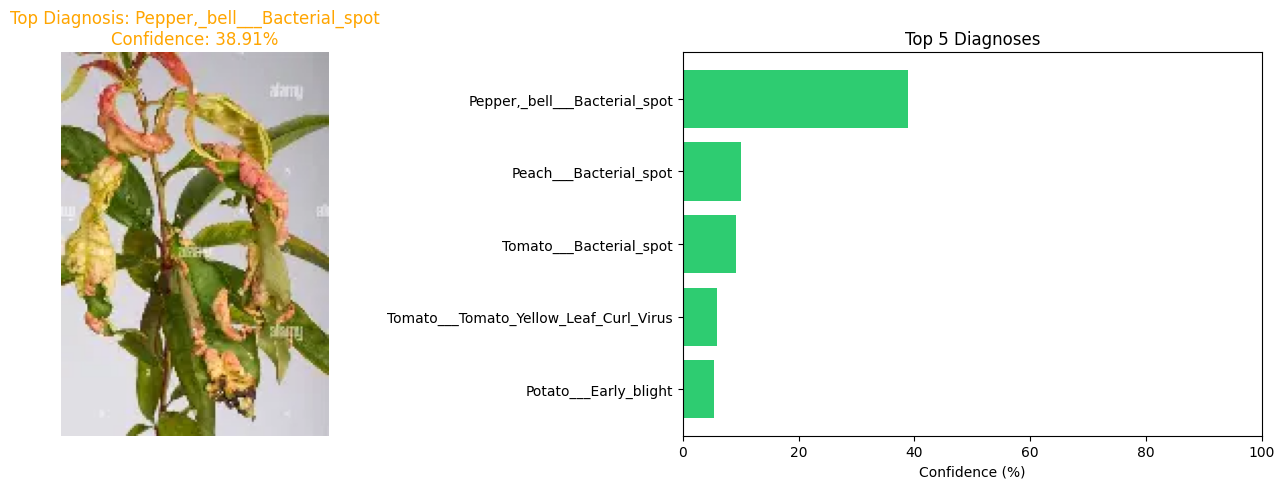

In [28]:
# Evaluation Cell 2: Test on Any Real Image (Upload or Test Set) with Confidence & Visualization

import torch
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

print("Upload a leaf image to test:")
uploaded = files.upload()

for filename in uploaded.keys():
    # 1. Load image
    raw_img = Image.open(filename).convert("RGB")

    # 2. Preprocess with ViT processor
    inputs = processor(raw_img, return_tensors="pt").to(model.device)

    # 3. Model Inference
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.nn.functional.softmax(outputs.logits, dim=-1)[0]

    # 4. Get Top 5 predictions
    top5_probs, top5_indices = torch.topk(probs, 5)

    # 5. Display Image and Bar Chart
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Show leaf image
    ax1.imshow(raw_img)
    ax1.axis("off")
    top_pred = id2label[top5_indices[0].item()]
    top_conf = top5_probs[0].item() * 100
    ax1.set_title(f"Top Diagnosis: {top_pred}\nConfidence: {top_conf:.2f}%", fontsize=12, color="green" if top_conf > 75 else "orange")

    # Show Top-5 probabilities bar chart
    labels = [id2label[idx.item()] for idx in top5_indices]
    percentages = [p.item() * 100 for p in top5_probs]

    y_pos = range(len(labels))[::-1]
    ax2.barh(y_pos, percentages, color="#2ecc71")
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(labels, fontsize=10)
    ax2.set_xlabel("Confidence (%)")
    ax2.set_xlim(0, 100)
    ax2.set_title("Top 5 Diagnoses")

    plt.tight_layout()
    plt.show()